# CSC 4110: MACHINE LEARNING
## Group G9 – Staff Attrition Prediction

### Module 6: Model Evaluation and Selection

**Task 5:** Model Evaluation and Selection

**Task Owner:** Owiye Sylvia  
**Registration Number:** COM/0044/23

**Dataset:** IBM HR Analytics Employee Attrition Dataset

**Classification Target:** Attrition

**Objective:** To build a machine learning pipeline, evaluate its performance using cross-validation, tune hyperparameters, analyse learning and validation curves, and select an appropriate decision threshold.

**Notebook:** `G09_U5_evaluation.ipynb`

In [1]:
# Import libraries and load the HR Attrition dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

# Load the original dataset
file_path = "/content/drive/MyDrive/CSC4110_G09/data/WA_Fn-UseC_-HR-Employee-Attrition.csv"

df = pd.read_csv(file_path)

# Display the dataset
print("Dataset shape:", df.shape)
display(df.head())

Mounted at /content/drive
Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
# Separate the target variable and remove unnecessary columns

# Convert Attrition into binary values: No = 0, Yes = 1
y = df["Attrition"].map({"No": 0, "Yes": 1})

# Remove target, employee ID, and constant columns
X = df.drop(columns=[
    "Attrition",
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
])

# Check the features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nAttrition distribution:")
print(y.value_counts())

Features shape: (1470, 30)
Target shape: (1470,)

Attrition distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [3]:
# Split the dataset while preserving the attrition class proportions

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the training and testing sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (1176, 30)
Testing features: (294, 30)

Training target distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Testing target distribution:
Attrition
0    247
1     47
Name: count, dtype: int64


In [4]:
# Identify numerical and categorical columns for preprocessing

numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Numerical features:")
print(numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

Number of numerical features: 23
Numerical features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Number of categorical features: 7
Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [5]:
# Build a preprocessing pipeline and combine it with Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Combine preprocessing and classification model
pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Fit the complete pipeline using training data only
pipe.fit(X_train, y_train)

print("Pipeline successfully created and fitted.")

Pipeline successfully created and fitted.


In [6]:
# Evaluate the pipeline using 5-fold stratified cross-validation

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate recall scores using training data only
cv_scores = cross_val_score(
    pipe,
    X_train,
    y_train,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

# Display cross-validation results
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation scores: [0.71052632 0.65789474 0.84210526 0.76315789 0.71052632]
Mean CV score: 0.7368421052631579
Standard deviation: 0.062274524032627517


In [7]:
# Tune Logistic Regression hyperparameters using GridSearchCV

from sklearn.model_selection import GridSearchCV

# Define the hyperparameter combinations
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

# Create the grid search
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

# Fit using training data only
grid.fit(X_train, y_train)

# Display the best results
print("Best parameters:", grid.best_params_)
print("Best CV recall score:", grid.best_score_)

Best parameters: {'model__C': 0.01, 'model__class_weight': 'balanced'}
Best CV recall score: 0.7578947368421052


In [8]:
# Evaluate the best model on the independent test set

from sklearn.metrics import recall_score

# Get the best model
best_model = grid.best_estimator_

# Make predictions on the test set
y_pred = best_model.predict(X_test)

# Calculate test recall
test_score = recall_score(y_test, y_pred)

print("Test Recall:", test_score)
print("Test Recall (%):", round(test_score * 100, 2), "%")

Test Recall: 0.723404255319149
Test Recall (%): 72.34 %


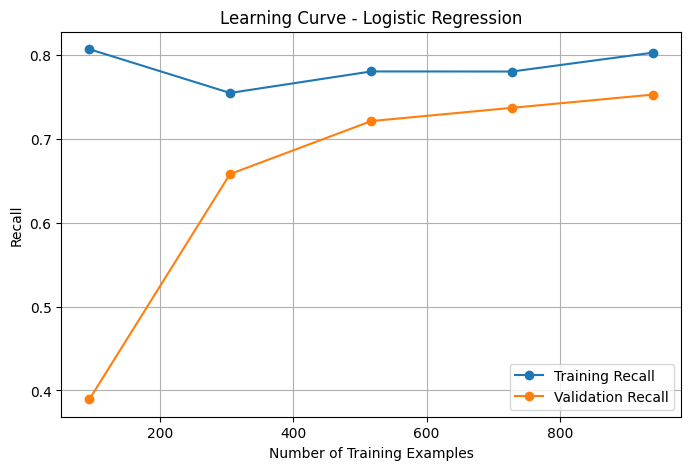

In [9]:
# Generate and save the learning curve for the best model

from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring="recall",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

# Calculate average scores
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

# Plot the learning curve
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training Recall")
plt.plot(train_sizes, validation_mean, marker="o", label="Validation Recall")

plt.title("Learning Curve - Logistic Regression")
plt.xlabel("Number of Training Examples")
plt.ylabel("Recall")
plt.legend()
plt.grid(True)

# Save the plot
plt.savefig(
    "/content/drive/MyDrive/CSC4110_G09/outputs/learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

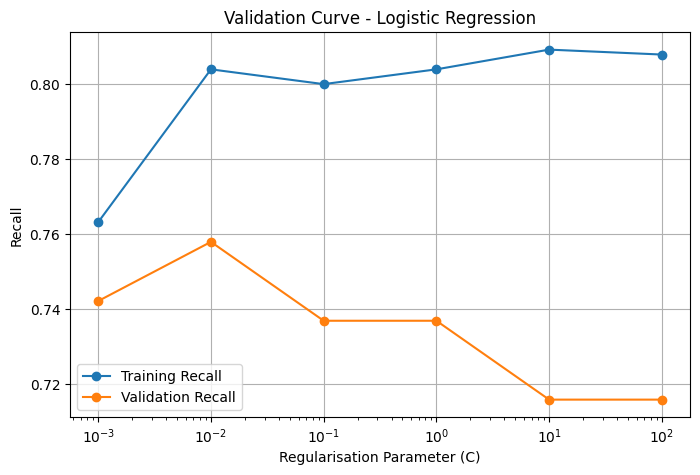

In [10]:
# Generate and save the validation curve for parameter C

from sklearn.model_selection import validation_curve

param_range = [0.001, 0.01, 0.1, 1, 10, 100]

train_scores, validation_scores = validation_curve(
    best_model,
    X_train,
    y_train,
    param_name="model__C",
    param_range=param_range,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

# Calculate average scores
train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

# Plot the validation curve
plt.figure(figsize=(8, 5))
plt.plot(param_range, train_mean, marker="o", label="Training Recall")
plt.plot(param_range, validation_mean, marker="o", label="Validation Recall")

plt.xscale("log")
plt.title("Validation Curve - Logistic Regression")
plt.xlabel("Regularisation Parameter (C)")
plt.ylabel("Recall")
plt.legend()
plt.grid(True)

# Save the plot
plt.savefig(
    "/content/drive/MyDrive/CSC4110_G09/outputs/validation_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Confusion Matrix:
[[192  55]
 [ 13  34]]


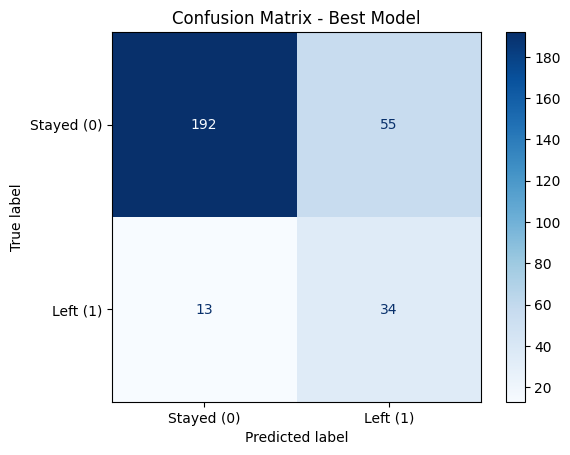

In [11]:
# Generate the confusion matrix for the best model

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (0)", "Left (1)"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Best Model")
plt.show()

In [12]:
# Compare model performance at decision thresholds 0.5 and 0.3

from sklearn.metrics import precision_score, recall_score, f1_score
from IPython.display import display as show_table

# Get predicted probabilities for employees leaving
y_prob = best_model.predict_proba(X_test)[:, 1]

# Store results for both thresholds
threshold_results = []

for threshold in [0.5, 0.3]:
    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

# Convert results into a DataFrame
threshold_results = pd.DataFrame(threshold_results)

# Display comparison
show_table(threshold_results)

,Threshold,Precision,Recall,F1 Score
0,0.5,0.382022,0.723404,0.500000
1,0.3,0.217822,0.936170,0.353414


### Decision Threshold Comparison and HR Recommendation

The model was evaluated using two decision thresholds:

| Metric | Threshold 0.5 | Threshold 0.3 |
|---|---:|---:|
| Precision | 38.20% | 21.78% |
| Recall | 72.34% | 93.62% |
| F1 Score | 0.5000 | 0.3534 |

When the threshold was reduced from 0.5 to 0.3, recall increased from 72.34% to 93.62%, while precision decreased from 38.20% to 21.78%.

**Recommendation:** The HR office should use a threshold of 0.3 because identifying employees who may leave is more important than avoiding false alarms in this scenario. A false positive can be handled through a supportive conversation, whereas missing an employee who is likely to leave may result in replacement costs.

The model should therefore be used as an early-warning support tool rather than for making employment decisions.

### Written Evaluation of Learning and Validation Curves

The learning curve shows that the model initially performs better on training data than on validation data. With only 94 training examples, training recall is 0.807 while validation recall is 0.389.

As the training size increases, validation recall improves to 0.753, while training recall remains at 0.803. The gap between the two scores becomes smaller.

**Conclusion:** The model initially shows overfitting, but performance improves as more training data is used. At the largest training size, the model is reasonably balanced, although a small degree of overfitting remains.

In [13]:
# Recalculate learning curve values for interpretation

from sklearn.model_selection import learning_curve

learning_sizes, learning_train_scores, learning_val_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring="recall",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

# Calculate average scores
learning_train_mean = learning_train_scores.mean(axis=1)
learning_val_mean = learning_val_scores.mean(axis=1)

# Create results table
learning_results = pd.DataFrame({
    "Training Size": learning_sizes,
    "Training Recall": learning_train_mean,
    "Validation Recall": learning_val_mean
})

print(learning_results.round(3).to_string(index=False))

 Training Size  Training Recall  Validation Recall
            94            0.807              0.389
           305            0.755              0.658
           517            0.780              0.721
           728            0.780              0.737
           940            0.803              0.753


In [14]:
# Recalculate validation curve values for interpretation

from sklearn.model_selection import validation_curve

validation_parameters = [0.001, 0.01, 0.1, 1, 10, 100]

val_train_scores, val_validation_scores = validation_curve(
    best_model,
    X_train,
    y_train,
    param_name="model__C",
    param_range=validation_parameters,
    cv=cv,
    scoring="recall",
    n_jobs=-1
)

# Calculate average scores
val_train_mean = val_train_scores.mean(axis=1)
val_validation_mean = val_validation_scores.mean(axis=1)

# Display the results
validation_results = pd.DataFrame({
    "C Parameter": validation_parameters,
    "Training Recall": val_train_mean,
    "Validation Recall": val_validation_mean
})

print(validation_results.round(3).to_string(index=False))

 C Parameter  Training Recall  Validation Recall
       0.001            0.763              0.742
       0.010            0.804              0.758
       0.100            0.800              0.737
       1.000            0.804              0.737
      10.000            0.809              0.716
     100.000            0.808              0.716


In [15]:
# Verify that all required assignment variables exist

required_variables = [
    "pipe",
    "cv_scores",
    "grid",
    "test_score",
    "threshold_results"
]

for variable in required_variables:
    print(variable, ":", "Available" if variable in globals() else "Missing")

pipe : Available
cv_scores : Available
grid : Available
test_score : Available
threshold_results : Available


In [16]:
import os

output_folder = "/content/drive/MyDrive/CSC4110_G09/outputs"

required_files = [
    "learning_curve.png",
    "validation_curve.png"
]

for filename in required_files:
    file_path = os.path.join(output_folder, filename)
    print(filename, ":", "Found" if os.path.isfile(file_path) else "Missing")

learning_curve.png : Found
validation_curve.png : Found


### Interpretation of the Validation Curve

The validation curve shows how the regularisation parameter (C) affects model performance.

The highest validation recall of 0.758 is achieved at C = 0.01. As C increases beyond 0.01, validation recall generally decreases, reaching 0.716 at C = 10 and C = 100.

The training and validation scores remain relatively close, indicating that the model generalises reasonably well across different parameter values.

**Conclusion:** C = 0.01 provides the best validation performance. This confirms the hyperparameter selected by GridSearchCV and suggests that stronger regularisation helps this model generalise better.

### Why the Test Set Must Be Used Only Once at the End

The test set must be kept separate from model training, preprocessing and hyperparameter tuning to prevent data leakage and biased performance estimates.

If the test set is repeatedly used to make modelling decisions, information from it can indirectly influence the model, making the final results less reliable.

Cross-validation and GridSearchCV are therefore performed using training data only. The test set is reserved for the final evaluation of the selected model on unseen data.

This provides a more objective estimate of how the model may perform on new employee data.